In [ ]:
!pip install -q tensorflow scikit-learn pandas matplotlib seaborn

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

print("TensorFlow version:", tf.__version__)

TensorFlow version: 2.20.0


In [ ]:
np.random.seed(42)

# Generate sensor data
temperature = np.random.uniform(20, 40, 300)
humidity = np.random.uniform(30, 90, 300)
light = np.random.uniform(100, 1000, 300)

# Create labels
# Alert if temperature > 32 OR humidity > 75
label = ((temperature > 32) | (humidity > 75)).astype(int)

# Create DataFrame
data = pd.DataFrame({
    "Temperature": temperature,
    "Humidity": humidity,
    "Light": light,
    "Label": label
})

print(data.head())

   Temperature   Humidity       Light  Label
0    27.490802  33.100903  252.041557      0
1    39.014286  61.881278  350.731305      1
2    34.639879  62.438107  259.309436      1
3    31.973170  68.245794  179.832280      0
4    23.120373  73.565480  208.572284      0


In [ ]:
print("Dataset shape:", data.shape)
print("\nDataset information:")
print(data.info())

print("\nClass distribution:")
print(data["Label"].value_counts())

Dataset shape: (300, 4)

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 300 entries, 0 to 299
Data columns (total 4 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   Temperature  300 non-null    float64
 1   Humidity     300 non-null    float64
 2   Light        300 non-null    float64
 3   Label        300 non-null    int64  
dtypes: float64(3), int64(1)
memory usage: 9.5 KB
None

Class distribution:
Label
1    179
0    121
Name: count, dtype: int64


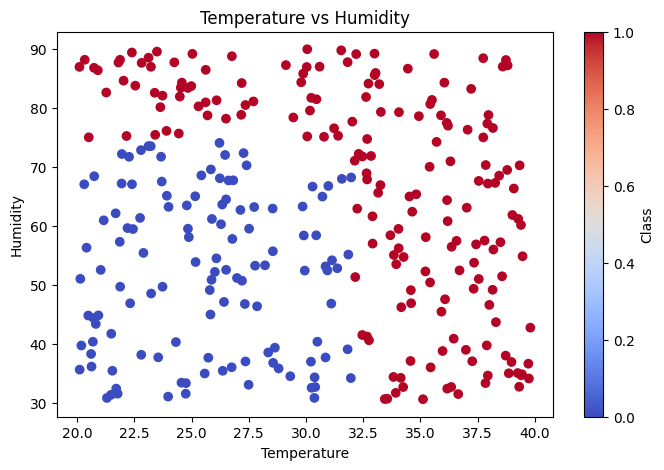

In [ ]:
plt.figure(figsize=(8, 5))

plt.scatter(
    data["Temperature"],
    data["Humidity"],
    c=data["Label"],
    cmap="coolwarm"
)

plt.xlabel("Temperature")
plt.ylabel("Humidity")
plt.title("Temperature vs Humidity")
plt.colorbar(label="Class")

plt.show()

In [ ]:
X = data[["Temperature", "Humidity", "Light"]]
y = data["Label"]

print("Input shape:", X.shape)
print("Output shape:", y.shape)

Input shape: (300, 3)
Output shape: (300,)


In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

Training samples: 240
Testing samples: 60


In [ ]:
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Before normalization:")
print(X_train.head())

print("\nAfter normalization:")
print(X_train_scaled[:5])

Before normalization:
     Temperature   Humidity       Light
98     20.508383  75.052264  238.926444
122    26.360069  35.472366  159.846641
54     31.958000  34.234125  488.493592
132    22.397307  67.093084  698.677499
20     32.237058  62.953600  266.068917

After normalization:
[[-1.61637117  0.84108668 -1.16508203]
 [-0.62109645 -1.35932439 -1.48025452]
 [ 0.33101844 -1.42816337 -0.17043238]
 [-1.29509645  0.39860276  0.6672554 ]
 [ 0.37848163  0.16847164 -1.05690573]]


In [ ]:
model = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(3,)),

    tf.keras.layers.Dense(16, activation="relu"),

    tf.keras.layers.Dense(8, activation="relu"),

    tf.keras.layers.Dense(1, activation="sigmoid")
])

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 16)             │            64 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 8)              │           136 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │             9 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 209 (836.00 B)

 Trainable params: 209 (836.00 B)

 Non-trainable params: 0 (0.00 B)

In [ ]:
model.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

print("Model compiled successfully!")

Model compiled successfully!


In [ ]:
history = model.fit(
    X_train_scaled,
    y_train,
    epochs=30,
    batch_size=16,
    validation_split=0.2,
    verbose=1
)

Epoch 1/30
12/12 ━━━━━━━━━━━━━━━━━━━━ 2s 34ms/step - accuracy: 0.5000 - loss: 0.7077 - val_accuracy: 0.4583 - val_loss: 0.7453
Epoch 2/30
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.5938 - loss: 0.6797 - val_accuracy: 0.5208 - val_loss: 0.7142
Epoch 3/30
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.6510 - loss: 0.6538 - val_accuracy: 0.6042 - val_loss: 0.6852
Epoch 4/30
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.7240 - loss: 0.6281 - val_accuracy: 0.6875 - val_loss: 0.6572
Epoch 5/30
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.7604 - loss: 0.6028 - val_accuracy: 0.6875 - val_loss: 0.6295
Epoch 6/30
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.7656 - loss: 0.5773 - val_accuracy: 0.7083 - val_loss: 0.6044
Epoch 7/30
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.7760 - loss: 0.5526 - val_accuracy: 0.7708 - val_loss: 0.5789
Epoch 8/30
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.8177 - loss: 0.5278 - val_accuracy: 0.7708 - val_loss

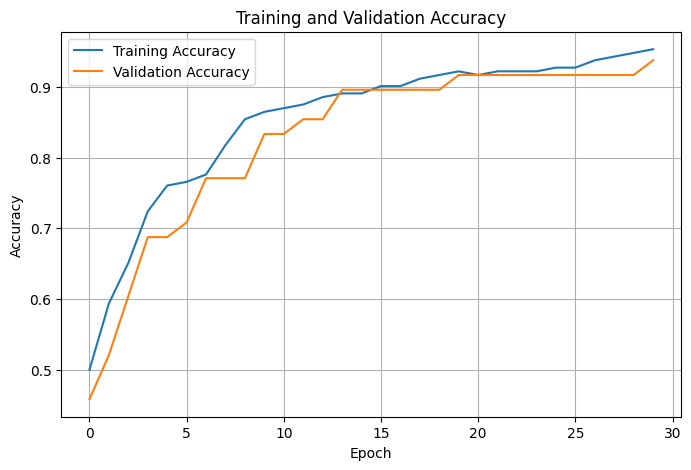

In [ ]:
plt.figure(figsize=(8, 5))

plt.plot(history.history["accuracy"], label="Training Accuracy")
plt.plot(history.history["val_accuracy"], label="Validation Accuracy")

plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Training and Validation Accuracy")
plt.legend()
plt.grid()

plt.show()

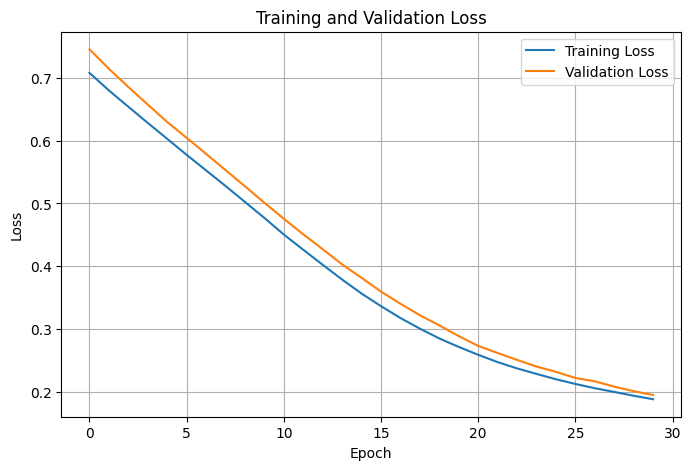

In [ ]:
plt.figure(figsize=(8, 5))

plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Training and Validation Loss")
plt.legend()
plt.grid()

plt.show()

In [ ]:
test_loss, test_accuracy = model.evaluate(
    X_test_scaled,
    y_test,
    verbose=0
)

print("Test Loss:", test_loss)
print("Test Accuracy:", test_accuracy)

Test Loss: 0.29214751720428467
Test Accuracy: 0.8666666746139526


In [ ]:
y_probability = model.predict(X_test_scaled)

y_pred = (y_probability >= 0.5).astype(int).flatten()

print("Predicted values:")
print(y_pred[:20])

print("\nActual values:")
print(y_test.values[:20])

2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 48ms/step
Predicted values:
[1 0 1 0 0 0 1 0 1 0 1 1 1 1 1 1 0 1 1 1]

Actual values:
[1 0 0 0 0 0 1 0 1 0 1 1 1 1 1 1 1 1 1 1]


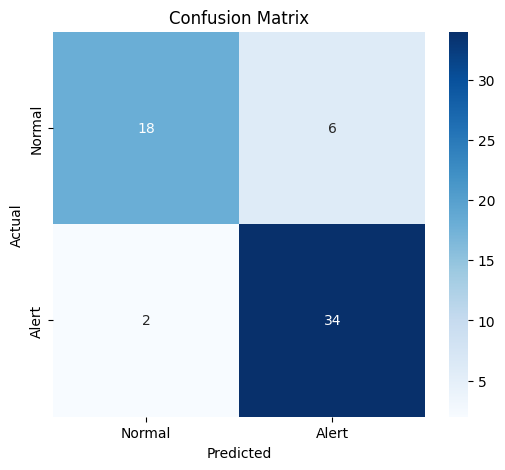

In [ ]:
cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(6, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Normal", "Alert"],
    yticklabels=["Normal", "Alert"]
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix")

plt.show()

In [ ]:
print(classification_report(
    y_test,
    y_pred,
    target_names=["Normal", "Alert"]
))

              precision    recall  f1-score   support

      Normal       0.90      0.75      0.82        24
       Alert       0.85      0.94      0.89        36

    accuracy                           0.87        60
   macro avg       0.88      0.85      0.86        60
weighted avg       0.87      0.87      0.86        60



In [ ]:
model.save("tinyml_sensor_model.keras")

print("Model saved successfully!")

Model saved successfully!


In [ ]:
import os

keras_size = os.path.getsize("tinyml_sensor_model.keras") / 1024

print(f"Keras model size: {keras_size:.2f} KB")

Keras model size: 27.38 KB


In [ ]:
converter = tf.lite.TFLiteConverter.from_keras_model(model)

tflite_model = converter.convert()

with open("tinyml_sensor_model.tflite", "wb") as f:
    f.write(tflite_model)

print("TensorFlow Lite model created successfully!")

Saved artifact at '/tmp/tmprt7fjta2'. The following endpoints are available:

* Endpoint 'serve'
  args_0 (POSITIONAL_ONLY): TensorSpec(shape=(None, 3), dtype=tf.float32, name='keras_tensor')
Output Type:
  TensorSpec(shape=(None, 1), dtype=tf.float32, name=None)
Captures:
  140454095133136: TensorSpec(shape=(), dtype=tf.resource, name=None)
  140454095134288: TensorSpec(shape=(), dtype=tf.resource, name=None)
  140454095132944: TensorSpec(shape=(), dtype=tf.resource, name=None)
  140454095132368: TensorSpec(shape=(), dtype=tf.resource, name=None)
  140454095134864: TensorSpec(shape=(), dtype=tf.resource, name=None)
  140454095131792: TensorSpec(shape=(), dtype=tf.resource, name=None)
TensorFlow Lite model created successfully!
